In [ ]:
# 1. Instalar la librería
!pip install kagglehub[pandas-datasets]

In [3]:

import pandas as pd

# descarga el dataset
path = "C:\\Modelos_I\\heart.csv"

print("Ruta del archivo:", path)

# cargar el CSV directamente
df = pd.read_csv(path)
# verificar que cargó correctamente
print(df.shape)
df.head()

Ruta del archivo: C:\Modelos_I\heart.csv
(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
#verificamos si tenemos valores nulos
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [8]:
pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.4 MB/s eta 0:00:35
   ---------------------------------------- 0.5/48.9 MB 1.4 MB/s eta 0:00:35
   ---------------------------------------- 0.5/48.9 MB 1.4 MB/s eta 0:00:35
    --------------------------------------- 0.8/48.9 MB 729.2 kB/s et

In [9]:
#importamos librerias
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

from xgboost import XGBClassifier

In [10]:
# 2. Convertir variables categóricas a numéricas
df_encoded = pd.get_dummies(
    df,
    columns=['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'],
    drop_first=True
)



In [11]:
# 3. Separar X e y
X = df_encoded.drop(columns=['HeartDisease'])
y = df_encoded['HeartDisease']


In [12]:
# 4. Split de Entrenamiento y Prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [13]:
#  XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    random_state=42
)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print("=== Reporte XGBoost ===")
print(classification_report(y_test, y_pred_xgb))

=== Reporte XGBoost ===
              precision    recall  f1-score   support

           0       0.87      0.88      0.87        82
           1       0.90      0.89      0.90       102

    accuracy                           0.89       184
   macro avg       0.88      0.89      0.88       184
weighted avg       0.89      0.89      0.89       184



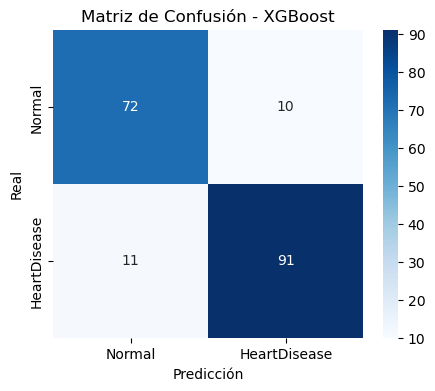

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Matriz de confusión para XGBoost
cm = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'HeartDisease'], yticklabels=['Normal', 'HeartDisease'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión - XGBoost')
plt.show()



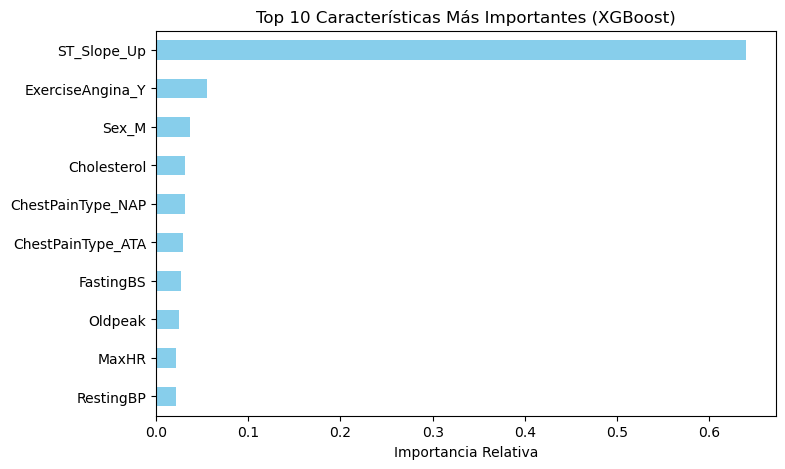

In [15]:
# 2. Gráfico de Importancia de Variables (Feature Importance)
plt.figure(figsize=(8,5))
feat_importances = pd.Series(xgb_model.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh', color='skyblue')
plt.title('Top 10 Características Más Importantes (XGBoost)')
plt.xlabel('Importancia Relativa')
plt.gca().invert_yaxis()
plt.show()

In [16]:
import joblib

# Guardar el modelo entrenado en un archivo binario
joblib.dump(xgb_model, 'modelo_xgboost.pkl')

print("¡Modelo guardado exitosamente como 'modelo_xgboost.pkl'!")

¡Modelo guardado exitosamente como 'modelo_xgboost.pkl'!
